# 07 — Try-On Bake-Off

**Goal:** Compare dedicated virtual try-on models against the current Gemini-based path. Try-on quality metric: does the rendered person visibly wear the exact garment? Does the body shape / face stay consistent?

**Pipeline:**
```
1 user reference photo + 1 garment photo
  → current Gemini path (image edit with combined prompt)
  → fal.ai try-on models (Kolors, Leffa, CatVTON, IDM-VTON)
  → side-by-side grid
  → cost + latency table
  → eyeball scores: garment fidelity, body consistency, overall
```

**Inputs needed:** Add a user reference photo (front-facing, plain background works best)
to `inputs/worn/` and a garment image to `inputs/worn/` — or they'll be loaded from your closet DB.


In [3]:
%matplotlib inline
import os, sys, io, base64
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
from dotenv import load_dotenv

load_dotenv(Path("..") / ".env")
sys.path.insert(0, str(Path("..")))

from lib.providers import GeminiProvider, FalProvider, all_providers, print_availability
from lib.images import resize_image

OUT_DIR = Path("../outputs/07")
OUT_DIR.mkdir(parents=True, exist_ok=True)

providers = all_providers()
print("Provider status:")
print_availability(providers)


Provider status:
  gemini       ✓ ready
  openrouter   ✓ ready
  fal          ✓ ready


User photo:    0VJj34XK0fWoDcNLtv7lD.jpg
Garment photo: 0p3JdJ7b6QApb0AlNxC-T.jpg


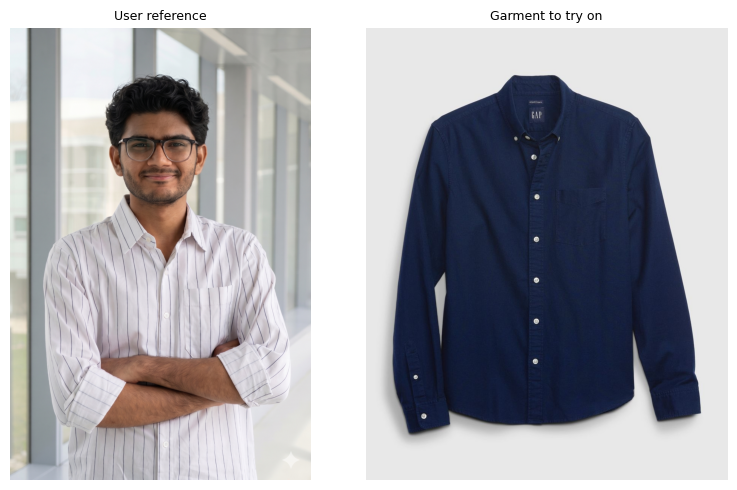


If these are wrong, set USER_PHOTO_PATH / GARMENT_PHOTO_PATH manually and re-run.


In [18]:
# ── Load inputs ───────────────────────────────────────────────────────────────
# USER_PHOTO:    a photo of the person (front-facing)
# GARMENT_PHOTO: a photo of the garment (flat-lay or worn, on plain background ideally)
#
# Convention: if inputs/worn/ has ≥2 images, the LAST one is the garment
#             and any earlier one is the user reference photo.
# Override USER_PHOTO_PATH / GARMENT_PHOTO_PATH to use specific files.
import glob

def _load_inputs():
    paths = sorted(Path("../inputs/worn").glob("*.jpg")) + sorted(Path("../inputs/worn").glob("*.jpeg")) + sorted(Path("../inputs/worn").glob("*.png"))
    paths = [p for p in paths if not p.name.startswith(".")]
    if len(paths) >= 2:
        return paths[0], paths[-1]
    db = sorted(glob.glob(os.path.expanduser("~/.closet/images/items/*.jpg")))
    if len(db) >= 2:
        return Path(db[0]), Path(db[1])
    if len(db) == 1:
        return Path(db[0]), Path(db[0])
    raise FileNotFoundError("Need at least 1 image in inputs/worn/ or ~/.closet/images/items/")

USER_PHOTO_PATH, GARMENT_PHOTO_PATH = _load_inputs()
USER_IMG    = resize_image(Image.open('prototypes/inputs/Untitled Folder/Gemini_Generated_Image_uz9u0quz9u0quz9u.png').convert('RGB'))
GARMENT_IMG = resize_image(Image.open(GARMENT_PHOTO_PATH))

print(f"User photo:    {USER_PHOTO_PATH.name}")
print(f"Garment photo: {GARMENT_PHOTO_PATH.name}")

fig, axes = plt.subplots(1, 2, figsize=(8, 5))
axes[0].imshow(USER_IMG);    axes[0].set_title("User reference", fontsize=9);  axes[0].axis("off")
axes[1].imshow(GARMENT_IMG); axes[1].set_title("Garment to try on", fontsize=9); axes[1].axis("off")
plt.tight_layout(); plt.show()

print("\nIf these are wrong, set USER_PHOTO_PATH / GARMENT_PHOTO_PATH manually and re-run.")


In [20]:
# ── Gemini baseline ──────────────────────────────────────────────────────────
TRYON_PROMPT = """You are a virtual try-on engine.
The first image is a reference photo of a person. The second image is a garment.
Generate a realistic photo of the person wearing that exact garment.
Preserve the person's face, body shape, and background. Only change what they are wearing.
Output a single composite image."""

gemini = providers["gemini"]
gemini_tryon = {}

if gemini.available:
    model_id = "gemini-3-pro-image-preview"
    print(f"[{model_id}]...")
    r = gemini.generate_image(model_id, TRYON_PROMPT, images=[USER_IMG, GARMENT_IMG])
    status = "✓" if r.ok else f"✗ {r.error}"
    print(f"  {status}  {r.latency_s:.1f}s  ${r.cost_usd:.4f}~")
    if r.ok:
        r.image.save(OUT_DIR / "07_gemini_tryon.png")
    gemini_tryon[model_id] = r
else:
    print("Gemini not available")


[gemini-3-pro-image-preview]...
  ✓  16.1s  $0.0390~


In [21]:
# ── fal.ai try-on models ──────────────────────────────────────────────────────
# All take human_image_url + garment_image_url.
fal = providers["fal"]
fal_tryon_results = {}

TRYON_MODELS = [
    ("fal-ai/kling/v1-5/kolors-virtual-try-on", "tryon"),
    ("fal-ai/leffa",                            "tryon"),
    ("fal-ai/cat-vton",                         "tryon"),
    ("fal-ai/idm-vton",                         "tryon"),
]

if fal.available:
    print("Uploading images to fal storage...")
    user_url    = fal.upload_image(USER_IMG)
    garment_url = fal.upload_image(GARMENT_IMG)
    print(f"  user_url:    {user_url[:60]}...")
    print(f"  garment_url: {garment_url[:60]}...")

    for model_id, pricing_kind in TRYON_MODELS:
        print(f"\n[{model_id}]...")
        args = {
            "human_image_url":   user_url,
            "garment_image_url": garment_url,
        }
        r = fal.generate_image(model_id, args, pricing_kind=pricing_kind)
        status = "✓" if r.ok else f"✗ {r.error[:80] if r.error else ''}"
        print(f"  {status}  {r.latency_s:.1f}s  ${r.cost_usd:.4f}~")
        if r.ok:
            safe = model_id.replace("/", "_").replace("-", "_")
            r.image.save(OUT_DIR / f"07_fal_{safe}.png")
        fal_tryon_results[model_id] = r
else:
    print("FAL_KEY not set — skipping fal try-on models")


Uploading images to fal storage...
  user_url:    https://v3b.fal.media/files/b/0aa022a6/X8sbbnLgYd_BwwywIY-rM...
  garment_url: https://v3b.fal.media/files/b/0aa022a6/9nQjUA02qqX9JAmScjTVr...

[fal-ai/kling/v1-5/kolors-virtual-try-on]...
  ✓  11.1s  $0.0700~

[fal-ai/leffa]...
  ✗ FalClientHTTPError: Path / not found  101.6s  $0.0000~

[fal-ai/cat-vton]...
  ✗ timeout after 120s  120.0s  $0.0300~

[fal-ai/idm-vton]...
  ✗ FalClientHTTPError: [{'type': 'missing', 'loc': ['body', 'description'], 'msg':   0.4s  $0.0500~


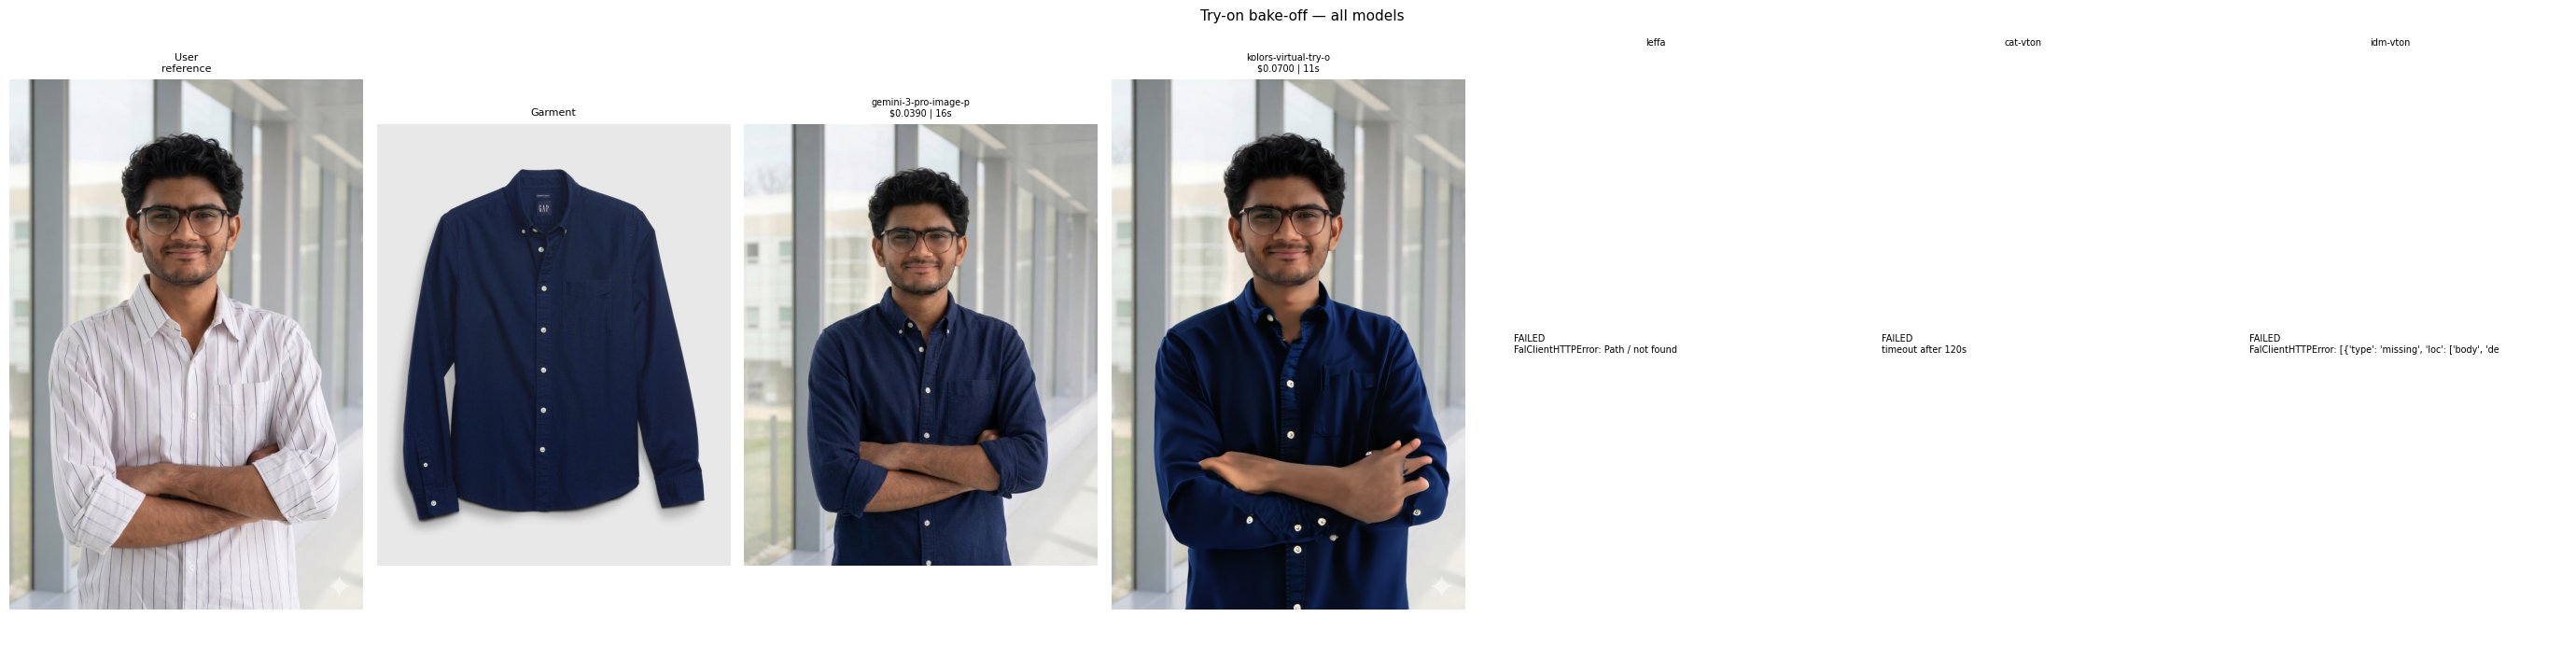

In [24]:
# ── Side-by-side grid ─────────────────────────────────────────────────────────
all_results = {**gemini_tryon, **fal_tryon_results}
model_ids = list(all_results.keys())
n = len(model_ids)

if n == 0:
    print("No results to display")
else:
    fig, axes = plt.subplots(1, n + 2, figsize=((n + 2) * 4, 7))
    axes[0].imshow(USER_IMG);    axes[0].set_title("User\nreference", fontsize=8); axes[0].axis("off")
    axes[1].imshow(GARMENT_IMG); axes[1].set_title("Garment", fontsize=8);          axes[1].axis("off")

    for ax, model_id in zip(axes[2:], model_ids):
        r = all_results[model_id]
        if r.ok:
            ax.imshow(r.image)
            ax.set_title(f"{model_id.split('/')[-1][:20]}\n${r.cost_usd:.4f} | {r.latency_s:.0f}s", fontsize=7)
        else:
            ax.text(0.1, 0.5, f"FAILED\n{r.error[:60] if r.error else ''}", 
                    transform=ax.transAxes, fontsize=7, va="center")
            ax.set_title(model_id.split("/")[-1][:20], fontsize=7)
        ax.axis("off")

    plt.suptitle("Try-on bake-off — all models", fontsize=11)
    plt.tight_layout(); plt.show()


In [11]:
# ── Metrics table ─────────────────────────────────────────────────────────────
rows = []
all_results_combined = {**gemini_tryon, **fal_tryon_results}
for model_id, r in all_results_combined.items():
    rows.append({
        "Model": model_id.split("/")[-1][:28],
        "Provider": r.provider,
        "Latency (s)": f"{r.latency_s:.1f}",
        "Cost": f"${r.cost_usd:.4f}~",
        "Garment fidelity (1-5)": "—",
        "Body consistency (1-5)": "—",
        "Overall (1-5)": "—",
        "Status": "✓" if r.ok else "✗",
    })

df = pd.DataFrame(rows)
print(df.to_string(index=False))
df.to_csv(OUT_DIR / "07_metrics.csv", index=False)
print("\nFill in eyeball scores after inspecting the grid above.")


                     Model Provider Latency (s)     Cost Garment fidelity (1-5) Body consistency (1-5) Overall (1-5) Status
gemini-3-pro-image-preview   gemini        22.4 $0.0390~                      —                      —             —      ✓

Fill in eyeball scores after inspecting the grid above.


## Decision note

Fill in after reviewing outputs and eyeball scores.

**Winner:** `_______`

**Why:**
- Garment fidelity score vs Gemini: 
- Body/face consistency: 
- Cost per try-on vs Gemini: 
- Latency: 

**Ship recommendation for `src/ai/tryon.ts`:**
```
provider: fal  (or keep gemini if no fal model matches quality)
model:    _______
endpoint args: human_image_url + garment_image_url
```

**Licensing note:** Check before shipping to production:
- CatVTON / IDM-VTON: CC-BY-NC research weights — commercial use requires author permission
- Kolors VTON: register commercial use at kwai-kolors@kuaishou.com

**Open questions:**
- Does quality improve with a cleaner garment photo (flat-lay vs worn)?
- Does Leffa outperform Kolors on Western clothing styles?
